In [3]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

####Data Read

In [4]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/car_prediction_data.csv')
len(df)

11914

In [5]:
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


####Data Preparation

In [6]:
df.columns

Index(['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP',
       'Engine Cylinders', 'Transmission Type', 'Driven_Wheels',
       'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style',
       'highway MPG', 'city mpg', 'Popularity', 'MSRP'],
      dtype='object')

In [7]:
df.dtypes

,0
Make,object
Model,object
Year,int64
Engine Fuel Type,object
Engine HP,float64
Engine Cylinders,float64
Transmission Type,object
Driven_Wheels,object
Number of Doors,float64
Market Category,object


In [8]:
df.describe()


,Year,Engine HP,Engine Cylinders,Number of Doors,highway MPG,city mpg,Popularity,MSRP
count,11914.000000,11845.00000,11884.000000,11908.000000,11914.000000,11914.000000,11914.000000,1.191400e+04
mean,2010.384338,249.38607,5.628829,3.436093,26.637485,19.733255,1554.911197,4.059474e+04
std,7.579740,109.19187,1.780559,0.881315,8.863001,8.987798,1441.855347,6.010910e+04
min,1990.000000,55.00000,0.000000,2.000000,12.000000,7.000000,2.000000,2.000000e+03
25%,2007.000000,170.00000,4.000000,2.000000,22.000000,16.000000,549.000000,2.100000e+04
50%,2015.000000,227.00000,6.000000,4.000000,26.000000,18.000000,1385.000000,2.999500e+04
75%,2016.000000,300.00000,6.000000,4.000000,30.000000,22.000000,2009.000000,4.223125e+04
max,2017.000000,1001.00000,16.000000,4.000000,354.000000,137.000000,5657.000000,2.065902e+06


In [9]:
#Make lowercase for all index and data
df.columns = df.columns.str.lower().str.replace(' ','_')
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='object')

In [10]:
#seperate the object types data
strings = list(df.dtypes[df.dtypes == 'object'].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [11]:
#df['make'].str.lower().str.replace(' ','_')

In [12]:
for col in strings:
  df[col] = df[col].str.lower().str.replace(' ','_')


In [13]:
df.dtypes

,0
make,object
model,object
year,int64
engine_fuel_type,object
engine_hp,float64
engine_cylinders,float64
transmission_type,object
driven_wheels,object
number_of_doors,float64
market_category,object


####Exploratory Data Analysis

In [14]:
for col in df.columns:
  print(col)
  print(df[col].unique()[:5]) #first five
  print(df[col].nunique()) #how many unique value
  print()

make
['bmw' 'audi' 'fiat' 'mercedes-benz' 'chrysler']
48

model
['1_series_m' '1_series' '100' '124_spider' '190-class']
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
['premium_unleaded_(required)' 'regular_unleaded'
 'premium_unleaded_(recommended)' 'flex-fuel_(unleaded/e85)' 'diesel']
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
['manual' 'automatic' 'automated_manual' 'direct_drive' 'unknown']
5

driven_wheels
['rear_wheel_drive' 'front_wheel_drive' 'all_wheel_drive'
 'four_wheel_drive']
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
['factory_tuner,luxury,high-performance' 'luxury,performance'
 'luxury,high-performance' 'luxury' 'performance']
71

vehicle_size
['compact' 'midsize' 'large']
3

vehicle_style
['coupe' 'convertible' 'sedan' 'wagon' '4dr_hatchback']
16

highway_mpg
[26 28 27 25 24]
59

city_mpg
[19 20 18 17 16]
69

popularity
[3916 3105  819  617 1013]
48

msrp
[46135 40650 36350 29450 345

<Axes: xlabel='msrp', ylabel='Count'>

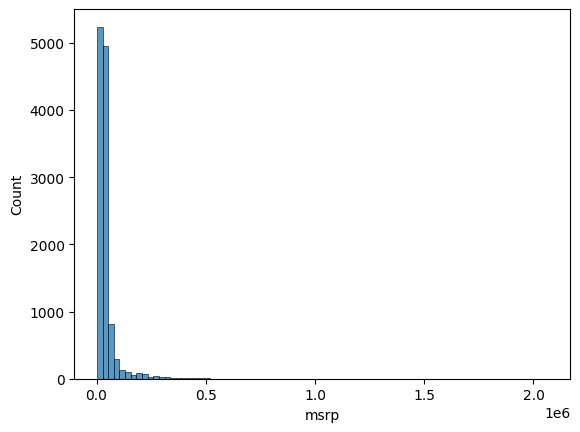

In [15]:
#Distribution of price

sns.histplot(df.msrp, bins = 80)

<Axes: xlabel='msrp', ylabel='Count'>

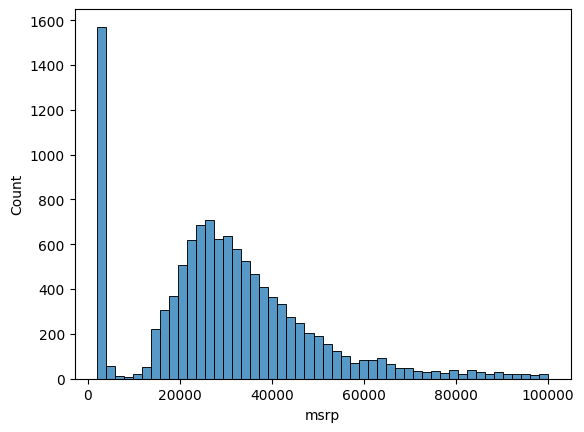

In [16]:
sns.histplot(df.msrp[df.msrp < 100000], bins = 50)

In [17]:
price_logs = np.log1p(df.msrp)
price_logs

,msrp
0,10.739349
1,10.612779
2,10.500977
3,10.290483
4,10.448744
...,...
11909,10.739024
11910,10.945018
11911,10.832122
11912,10.838031


<Axes: xlabel='msrp', ylabel='Count'>

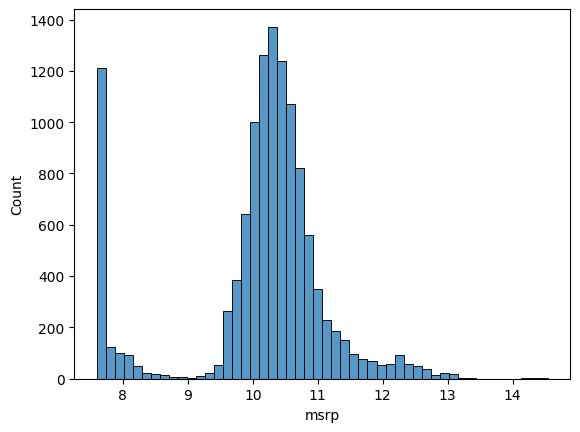

In [18]:
sns.histplot(price_logs, bins = 50)

this is a normal distribution data for the price.

In [19]:
#check missing values
df.isnull().sum()


,0
make,0
model,0
year,0
engine_fuel_type,3
engine_hp,69
engine_cylinders,30
transmission_type,0
driven_wheels,0
number_of_doors,6
market_category,3742


#### Split data: Train,vaidation and test data

- train 60%
- validation 20%
- test 20%


In [20]:
np.random.seed(2)

n = len(df)

n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)

idx = np.arange(n)
np.random.shuffle(idx)

df_shuffled = df.iloc[idx]

df_train = df_shuffled.iloc[:n_train].copy()
df_val = df_shuffled.iloc[n_train:n_train+n_val].copy()
df_test = df_shuffled.iloc[n_train+n_val:].copy()

In [21]:
y_train_orig = df_train.msrp.values
y_val_orig = df_val.msrp.values
y_test_orig = df_test.msrp.values

y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

In [22]:
print(df_train.shape)
print(df_val.shape)
print(df_test.shape)

(7150, 15)
(2382, 15)
(2382, 15)


In [23]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657


####Linear Regression

In [30]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)

    return w[0], w[1:]

####BaseLine Solution

In [45]:
df_train.dtypes

,0
make,object
model,object
year,int64
engine_fuel_type,object
engine_hp,float64
engine_cylinders,float64
transmission_type,object
driven_wheels,object
number_of_doors,float64
market_category,object


In [46]:
base = ['engine_hp','engine_cylinders','highway_mpg','city_mpg','popularity']
X_train = df_train[base].values

In [47]:
df_train[base].fillna(0).values

array([[ 148.,    4.,   33.,   24., 1385.],
       [ 132.,    4.,   32.,   25., 2031.],
       [ 148.,    4.,   37.,   28.,  640.],
       ...,
       [ 285.,    6.,   22.,   17.,  549.],
       [ 563.,   12.,   21.,   13.,   86.],
       [ 200.,    4.,   31.,   22.,  873.]])

In [48]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

In [49]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [50]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression(X_train, y_train)

In [51]:
y_pred = w_0 + X_train.dot(w)

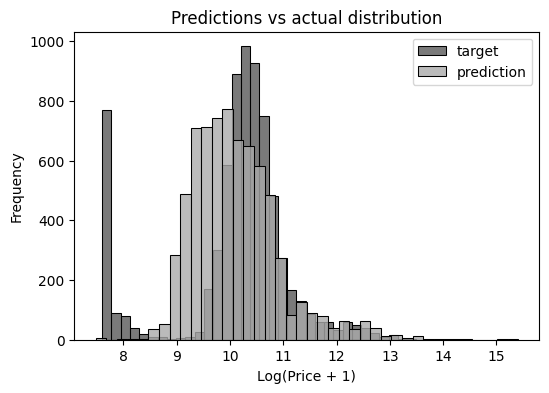

In [52]:
plt.figure(figsize=(6, 4))

sns.histplot(y_train, label='target', color='#222222', alpha=0.6, bins=40)
sns.histplot(y_pred, label='prediction', color='#aaaaaa', alpha=0.8, bins=40)

plt.legend()

plt.ylabel('Frequency')
plt.xlabel('Log(Price + 1)')
plt.title('Predictions vs actual distribution')

plt.show()

####RMSE

In [53]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [54]:
rmse(y_train, y_pred)

np.float64(0.7554192603920132)

In [55]:
X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)

In [56]:
baseline_rmse = rmse(y_val, y_pred)
print('baseline Validation rmse: ' , baseline_rmse)

baseline Validation rmse:  0.761653099130156


####Simple feature engineering

In [58]:
#add one feature more
def prepare_X(df):
    df = df.copy()

    features = base + ['year']

    df_num = df[features]
    df_num = df_num.fillna(0)

    X = df_num.values

    return X

In [59]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)

year_rmse = rmse(y_val, y_pred)

print("Baseline RMSE:", baseline_rmse)
print("With year RMSE:", year_rmse)

Baseline RMSE: 0.761653099130156
With year RMSE: 0.5172055461055305


In [60]:
if year_rmse < baseline_rmse:
    print("Adding year improved validation RMSE.")
else:
    print("Adding year did not improve validation RMSE.")

Adding year improved validation RMSE.


####catagorical feature add

In [72]:
categorical_columns = [
    'make',
    'model',
    'engine_fuel_type',
    'driven_wheels',
    'market_category',
    'vehicle_size',
    'vehicle_style'
]

categorical = {}

for c in categorical_columns:
    categorical[c] = list(
        df_train[c].value_counts().head().index
    )

categorical

{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'],
 'model': ['silverado_1500', 'tundra', 'f-150', 'sierra_1500', 'tacoma'],
 'engine_fuel_type': ['regular_unleaded',
  'premium_unleaded_(required)',
  'premium_unleaded_(recommended)',
  'flex-fuel_(unleaded/e85)',
  'diesel'],
 'driven_wheels': ['front_wheel_drive',
  'rear_wheel_drive',
  'all_wheel_drive',
  'four_wheel_drive'],
 'market_category': ['crossover',
  'flex_fuel',
  'luxury',
  'hatchback',
  'luxury,performance'],
 'vehicle_size': ['compact', 'midsize', 'large'],
 'vehicle_style': ['sedan',
  '4dr_suv',
  'coupe',
  'convertible',
  '4dr_hatchback']}

In [73]:
def prepare_X(df):
    df = df.copy()

    df['age'] = 2017 - df['year']
    features = base + ['age']

    for v in [2, 3, 4]:
        column = 'num_doors_%d' % v

        df[column] = (
            df['number_of_doors'] == v
        ).astype(int)

        features.append(column)

    for name, values in categorical.items():
        for value in values:
            column = '%s_%s' % (name, value)

            df[column] = (
                df[name] == value
            ).astype(int)

            features.append(column)

    df_num = df[features].fillna(0)

    return df_num.values

In [74]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    w = np.linalg.lstsq(X, y, rcond=None)[0]

    return w[0], w[1:]

In [77]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)

categorical_score = rmse(y_val, y_pred)

pd.DataFrame({
    'features': ['Baseline', 'With age', 'With categories'],
    'validation_rmse': [
        baseline_rmse,
        year_rmse,
        categorical_score
    ]
})

,features,validation_rmse
0,Baseline,0.761653
1,With age,0.517206
2,With categories,0.460815


####Add regularization to your training function

In [67]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)

    penalty = r * np.eye(XTX.shape[0])

    # Do not penalize the intercept
    penalty[0, 0] = 0

    XTX = XTX + penalty

    # Solve directly instead of explicitly calculating the inverse
    w = np.linalg.solve(XTX, X.T.dot(y))

    return w[0], w[1:]

The change is:
$$
X^\top X
\quad\longrightarrow\quad
X^\top X+rI
$$
with the intercept excluded from the penalty.
- r controls regularization strength.
- w contains the learned coefficients.
- Larger r shrinks coefficients more strongly.

In [78]:
#try one values
X_train = prepare_X(df_train)
X_val = prepare_X(df_val)

w_0, w = train_linear_regression_reg(
    X_train, y_train, r=0.01
)

y_pred = w_0 + X_val.dot(w)

print("Without regularization:", categorical_score)
print("With regularization:", rmse(y_val, y_pred))

Without regularization: 0.46081530985737534
With regularization: 0.4608154958375689


In [79]:
###tuning r

tuning_results = [{
    'r': 0.0,
    'validation_rmse': categorical_score
}]

for r in [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]:
    w_0, w = train_linear_regression_reg(
        X_train, y_train, r=r
    )

    y_pred = w_0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    tuning_results.append({
        'r': r,
        'validation_rmse': score
    })

tuning_table = pd.DataFrame(tuning_results)

tuning_table.sort_values('validation_rmse')

,r,validation_rmse
0,0.00000,0.460815
1,0.00001,0.460815
2,0.00010,0.460815
3,0.00100,0.460815
4,0.01000,0.460815
5,0.10000,0.460817
6,1.00000,0.460845
7,10.00000,0.461414


In [80]:
best_row = tuning_table.loc[
    tuning_table['validation_rmse'].idxmin()
]

best_r = float(best_row['r'])

print("Best r:", best_r)
print("Best validation RMSE:", best_row['validation_rmse'])
print("Original baseline RMSE:", baseline_rmse)

Best r: 0.0
Best validation RMSE: 0.46081530985737534
Original baseline RMSE: 0.761653099130156
